In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
%matplotlib inline

DATA_DIR = Path("data/processed")

# Chart colours: blue/orange categorical, blue<->red diverging, muted greys for axes
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "figure.dpi": 110,
})

## 1. Load data

In [4]:
train = pd.read_csv(DATA_DIR / "fraudTrain_features.csv")

X_train_full = train.drop(columns=["is_fraud"]).astype("float32")
y_train_full = train["is_fraud"]
cols = list(X_train_full.columns)
print(f"train: {len(X_train_full):,} rows, {len(cols):,} features, fraud rate {y_train_full.mean():.3%}")

train: 1,296,675 rows, 110 features, fraud rate 0.579%


## 2. Train / validation split

The engineered training data remains in chronological order. The first 80% is used to fit the model, while the final 20% is held out as an out-of-time validation period for selecting the regularisation strength `C` and the fraud decision threshold. The test set is not loaded or evaluated in this notebook.

In [5]:
cut = int(len(X_train_full) * 0.8)
X_tr, y_tr = X_train_full.iloc[:cut], y_train_full.iloc[:cut]
X_val, y_val = X_train_full.iloc[cut:], y_train_full.iloc[cut:]

split_sizes = pd.DataFrame({
    "split": ["fit", "validation"],
    "rows": [len(X_tr), len(X_val)],
    "fraud": [y_tr.sum(), y_val.sum()],
    "fraud rate": [f"{y_tr.mean():.3%}", f"{y_val.mean():.3%}"],
}).set_index("split")
split_sizes

,rows,fraud,fraud rate
split,,,
fit,1037340,5968,0.575%
validation,259335,1538,0.593%


## 3. Model pipeline

- **Scaling.** Continuous features are standardised so each coefficient means "change in log-odds per 1 standard deviation". The 0/1 columns are left as-is. The scaler is fit on the training rows only, inside the pipeline.
- **`class_weight="balanced"`.** Fraud cases receive higher weight so the model cannot ignore the minority class. Because this affects probability calibration, the decision threshold is tuned on validation data rather than fixed at 0.5.
- **Regularisation.** L2 penalty; its strength `C` is chosen on the validation set.


In [6]:
binary_columns = [c for c in X_train_full.columns if X_train_full[c].isin([0, 1]).all()]
print(f"{len(cols) - len([c for c in binary_columns if c in cols])} continuous (scaled), {len([c for c in binary_columns if c in cols])} binary (left as 0/1)")


def make_model(C, columns):
    continuous = [c for c in columns if c not in binary_columns]
    return Pipeline([
        ("scale", ColumnTransformer(
            [("continuous", StandardScaler(), continuous)],
            remainder="passthrough",
            verbose_feature_names_out=False,
        )),
        ("logreg", LogisticRegression(C=C, class_weight="balanced", max_iter=3000)),
    ])


def best_f1_threshold(y, proba):
    precision, recall, thresholds = precision_recall_curve(y, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return float(thresholds[np.argmax(f1)])


def scores_at(y, proba, threshold):
    alert = proba >= threshold
    caught = int((alert & (y == 1)).sum())
    return {
        "alerts": int(alert.sum()),
        "frauds caught": caught,
        "false alarms": int(alert.sum()) - caught,
        "precision": caught / max(int(alert.sum()), 1),
        "recall": caught / int((y == 1).sum()),
    }


28 continuous (scaled), 82 binary (left as 0/1)


## 4. Hyperparameter tuning and model selection

We evaluate several values of the Logistic Regression regularisation parameter `C`.

Each candidate model is trained on the fitting portion (`X_tr`, `y_tr`) and evaluated on the validation portion (`X_val`, `y_val`) using PR-AUC. The value of `C` with the highest validation PR-AUC is selected.

After selecting the best `C`, the standalone fraud threshold is chosen on the validation predictions by maximising F1-score. The test set is not used.

In [12]:
C_GRID = [0.00001, 0.0001, 0.001, 0.01, 0.1]

c_search, best = [], None
for C in C_GRID:
    model = make_model(C, cols).fit(X_tr[cols], y_tr)
    proba = model.predict_proba(X_val[cols])[:, 1]
    pr_auc = average_precision_score(y_val, proba)
    c_search.append({"C": C, "val PR-AUC": pr_auc})
    if best is None or pr_auc > best["val PR-AUC"]:
        best = {"C": C, "val PR-AUC": pr_auc, "val_proba": proba}

best["threshold"] = best_f1_threshold(y_val, best["val_proba"])
print(
    f"Best C: {best['C']}; validation PR-AUC: {best['val PR-AUC']:.4f}; "
    f"standalone threshold: {best['threshold']:.3f}"
)
pd.DataFrame(c_search).round(4)

final_model = make_model(best["C"], cols).fit(X_train_full[cols], y_train_full)


Best C: 0.001; validation PR-AUC: 0.4196; standalone threshold: 0.945


## 5. Validation performance at the selected threshold

The table below shows the selected Logistic Regression model's validation performance.

- **Alerts**: transactions classified as fraud
- **Frauds caught**: actual fraud cases correctly identified
- **False alarms**: legitimate transactions incorrectly flagged
- **Precision**: proportion of alerts that are fraud
- **Recall**: proportion of all fraud cases detected

This threshold is selected using validation data and will remain fixed for any later final evaluation.

In [8]:
pd.DataFrame({f"standalone ({best['threshold']:.3f})": scores_at(y_val, best["val_proba"], best["threshold"])}).T.round(3)


,alerts,frauds caught,false alarms,precision,recall
standalone (0.945),2162.0,1076.0,1086.0,0.498,0.7


## 6. Model details

The model uses all 110 features.


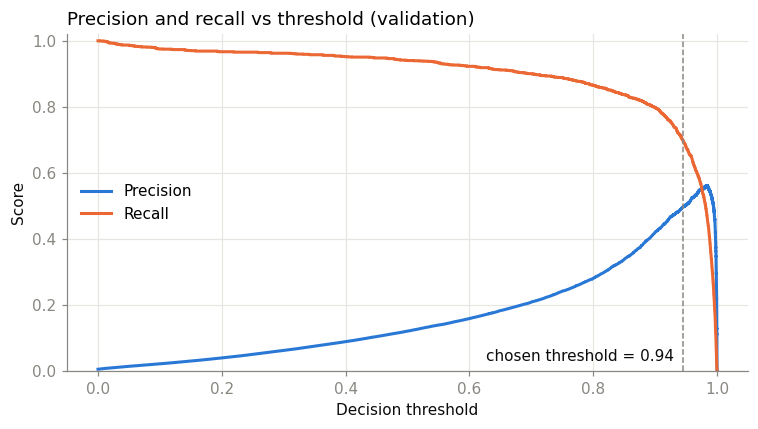

In [9]:
val_proba = best["val_proba"]
threshold = best["threshold"]

precision, recall, thresholds = precision_recall_curve(y_val, val_proba)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, precision[:-1], color=BLUE, label="Precision")
ax.plot(thresholds, recall[:-1], color=ORANGE, label="Recall")
ax.axvline(threshold, color=MUTED, linestyle="--", linewidth=1)
ax.annotate(f"chosen threshold = {threshold:.2f}", (threshold, 0.03),
            xytext=(-6, 0), textcoords="offset points", ha="right", color=INK)
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.02)
ax.set_title("Precision and recall vs threshold (validation)", loc="left")
ax.legend(frameon=False, loc="center left")
plt.tight_layout()
plt.show()


## 7. Coefficients and odds ratios

Because multicollinearity was removed in preprocessing, the coefficients can be read individually:

- **Continuous features:** odds ratio = multiplicative change in the odds of fraud for a **1 standard deviation** increase.
- **Dummies:** odds ratio compares the feature to its baseline category.

Odds ratio > 1 means higher fraud risk, < 1 lower. These are associations within simulated data, not causal effects.


In [10]:
feature_names = final_model.named_steps["scale"].get_feature_names_out()
coefs = pd.DataFrame({
    "feature": feature_names,
    "coef": final_model.named_steps["logreg"].coef_[0],
})
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs["scaled"] = ~coefs["feature"].isin(binary_columns)
coefs = coefs.reindex(coefs["coef"].abs().sort_values(ascending=False).index).reset_index(drop=True)
coefs.head(20).round(3)

,feature,coef,odds_ratio,scaled
0,amt_is_large,2.766,15.900,False
1,category_shopping_pos,-2.095,0.123,False
2,beh_log_amt_sum_24h,2.027,7.592,True
3,category_shopping_net,-1.884,0.152,False
4,category_misc_net,-1.568,0.208,False
5,log_amt,-1.285,0.277,True
6,category_entertainment,-1.220,0.295,False
7,hour_cos,1.054,2.868,True
8,beh_txn_count_24h,-1.048,0.351,True
9,category_travel,-0.933,0.394,False


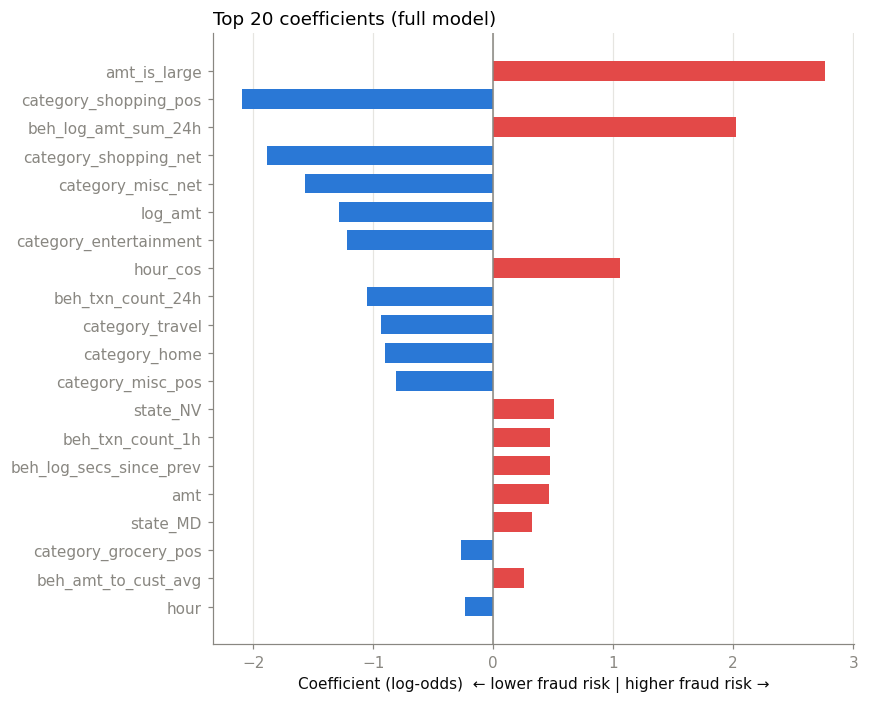

In [11]:
top = coefs.head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top["feature"], top["coef"], color=np.where(top["coef"] > 0, RED, BLUE), height=0.7)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Coefficient (log-odds)  ← lower fraud risk | higher fraud risk →")
ax.set_title("Top 20 coefficients (full model)", loc="left")
plt.tight_layout()
plt.show()

## 8. Validation results summary

The logistic-regression hyperparameter `C` and the standalone fraud threshold are selected using validation PR-AUC and validation F1, respectively. Test labels are not loaded or evaluated in this notebook.

| Model | Validation PR-AUC |
|---|---:|
| Logistic Regression | 0.420 |
